Load data

In [ ]:
from fastai.vision.all import *
from fastai.callback.all import *

path = Path("/Users/linea/Kth/År4/Deep Learning/Project/DD2424_Project/oxford-iiit-pet")
files = get_image_files(path/"images")
files = L(files).shuffle() # shuffel training data

Binary Classification Problem: Training only the classification layer for 3 epochs.

epoch,train_loss,valid_loss,accuracy,time
0,0.174353,0.023772,0.990528,00:51
1,0.067251,0.013449,0.994587,00:52
2,0.031328,0.010095,0.996617,00:51


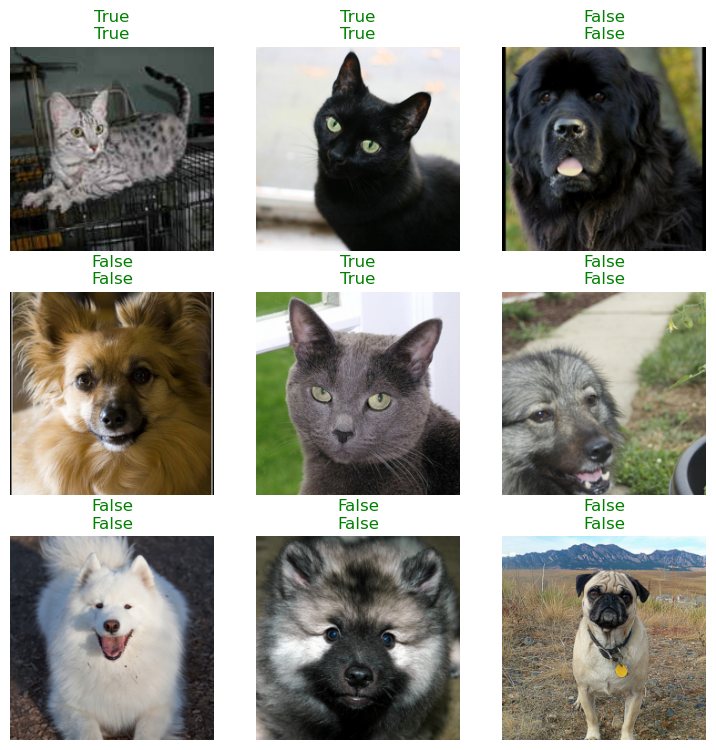

In [ ]:

# Labeling function: Uppercase = Cat (True), Lowercase = Dog (False)
def label_func(f): return f[0].isupper()
pat = r'^(.*)_\d+.jpg'

# Create DataLoaders
dls = ImageDataLoaders.from_name_func(
    path, files, label_func, 
    item_tfms=Resize(224), 
    valid_pct=0.2, 
    seed=42
)

#dls.show_batch()

# Initialize and finetune the Transfer Learning model
learn = vision_learner(dls, resnet18, metrics=accuracy)
learn.fit_one_cycle(3)

# Evaluation
learn.predict(files[0])
learn.show_results()

Multi-class Classification Problem - Linear Probing (Training only the last classification layer for 4 epochs.)

<div></div>

Suggested LR: 0.0006918309954926372


epoch,train_loss,valid_loss,error_rate,time
0,1.294031,0.328033,0.104195,01:18


epoch,train_loss,valid_loss,error_rate,time
0,0.539697,0.391928,0.122463,01:43
1,0.326754,0.224800,0.066306,01:47


epoch,train_loss,valid_loss,error_rate,time
0,1.022601,2.275813,0.512179,01:55
1,0.779011,0.473051,0.150203,02:00
2,0.389415,0.298072,0.098106,01:57


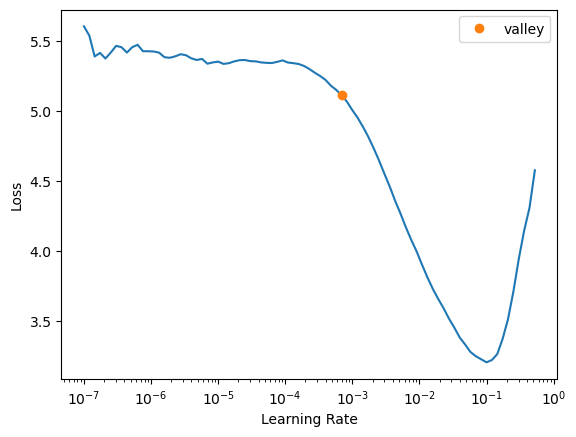

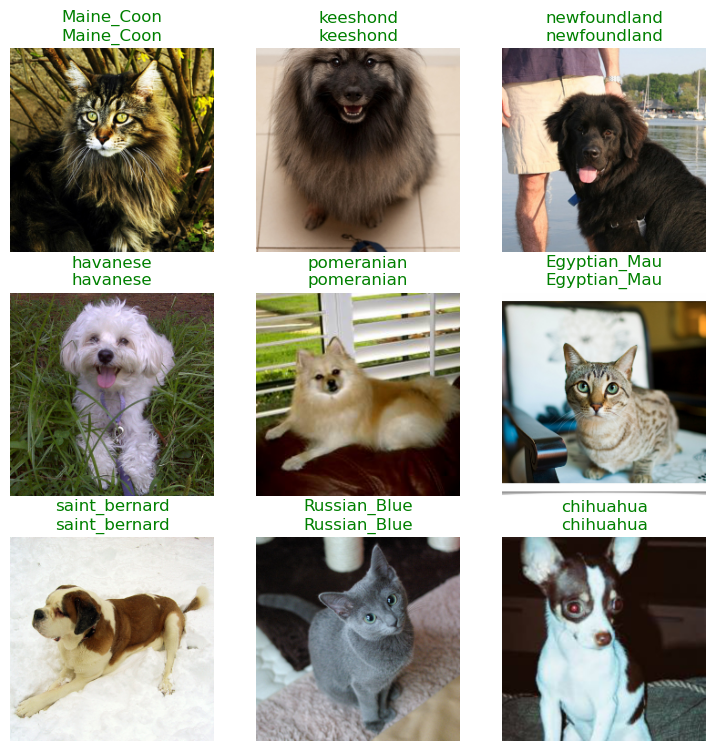

In [ ]:
# The regex patter grabs the breed name before the last underscore and digits
pat = r'^(.*)_\d+.jpg'

# Create DataLoaders for the 37 breeds
dls_multi = ImageDataLoaders.from_name_re(
    path, files, pat, 
    item_tfms=Resize(448), # Resize larger first for better augmentation
    batch_tfms=aug_transforms(size=224), # Standard augmentation for breeds
    valid_pct=0.2, 
    seed=42
)

# Initialize the learner 
learn = vision_learner(dls_multi, resnet18, metrics=accuracy)

# Perform Linear Probing
suggested_lr = learn.lr_find()
print(f"Suggested LR: {suggested_lr.valley}")

learn.fit_one_cycle(4, lr_max=suggested_lr.valley)
learn.show_results()

Multi-Class Classification Problem: Fine-tuning Network

Strategy 1; Fine-tune l layers simultaneously

In [ ]:
# Strategy 1:
def train_strategy_simultaneous(dls, wd=0.01):
    #epochs = 2

    epochs = 2

    results = []
    for l in range(1,4):
        print(l)
        learn = vision_learner(dls, resnet18, metrics=accuracy, wd=wd)
        learn.freeze_to(-l)
        # Find a new learning rate for each level of unfreezing
        suggestion =learn.lr_find() 
        lr = suggestion.valley 
        learn.fit_one_cycle(epochs, lr_max =lr)

        acc = learn.validate()[1]
        results.append((l, acc))

        #epochs += 2

    return learn, results

Strategy 2: Gradual un-freezing

In [11]:
# Strategy 2:
def train_strategy_gradual(dls, wd=0.01):
    learn = vision_learner(dls, resnet18, metrics=accuracy, wd=wd)

    for l in range(1,4):
        print(l)
        learn.freeze_to(-l)
        # Find a new learning rate for each level of unfreezing
        suggestion =learn.lr_find()
        lr = suggestion.valley 
        #learn.fit_one_cycle(2, lr_max = lr)

        learn.fit_one_cycle(1, lr_max = lr)

    return learn


Limited data tuning


Running: 1% Data + Aug
1


<div></div>

epoch,train_loss,valid_loss,accuracy,time
0,5.377809,6.083543,0.142857,00:00


2


<div></div>

...

3


<div></div>

epoch,train_loss,valid_loss,accuracy,time
0,3.798916,3.564896,0.071429,00:00


Strat 1 Final Accuracy for 1% Data + Aug: 0.0000
Strat 2 Final Accuracy for 1% Data + Aug: 0.0714

--- Summary Table ---
               Strategy 1 (Sim)  Strategy 2 (Grad)
1% Data + Aug               0.0           0.071429


<Axes: title={'center': 'Comparison of Training Strategies'}>

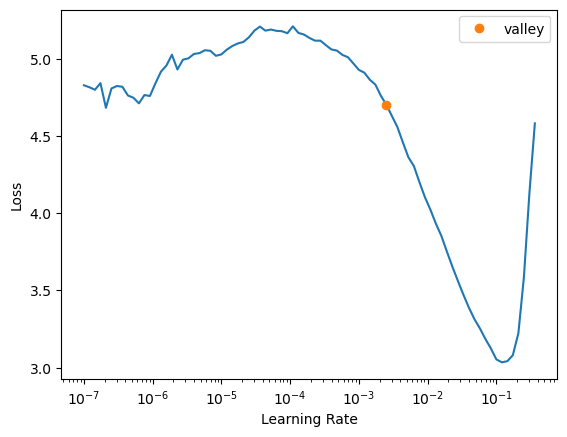

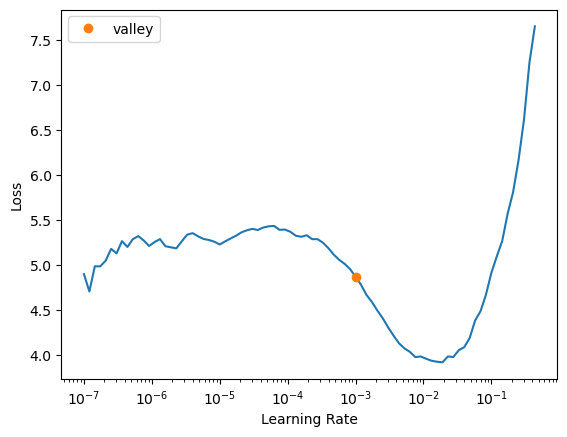

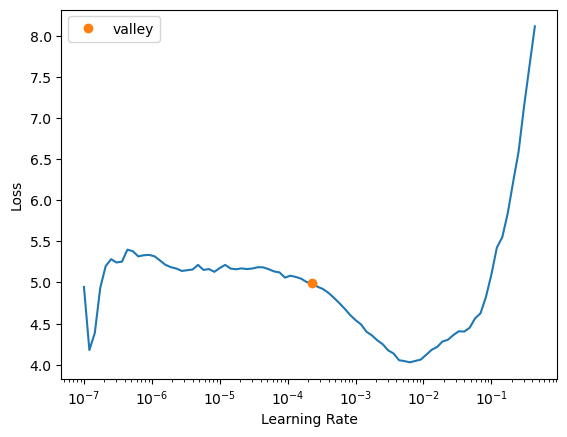

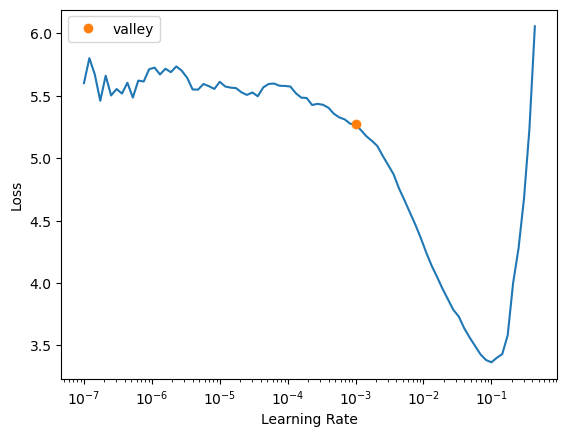

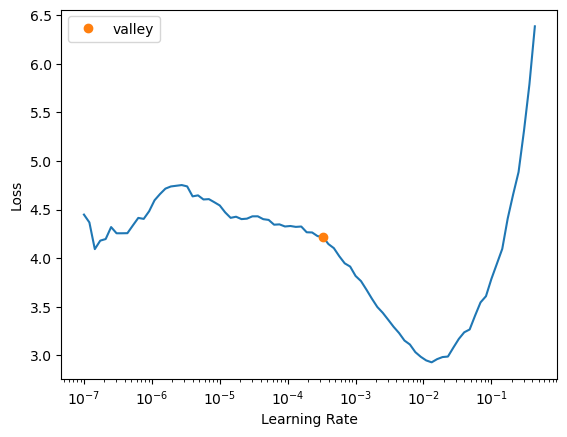

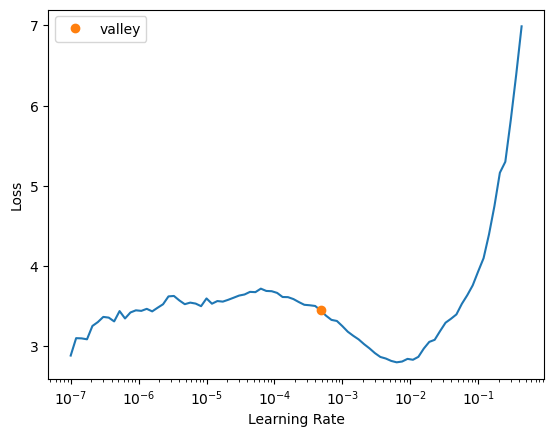

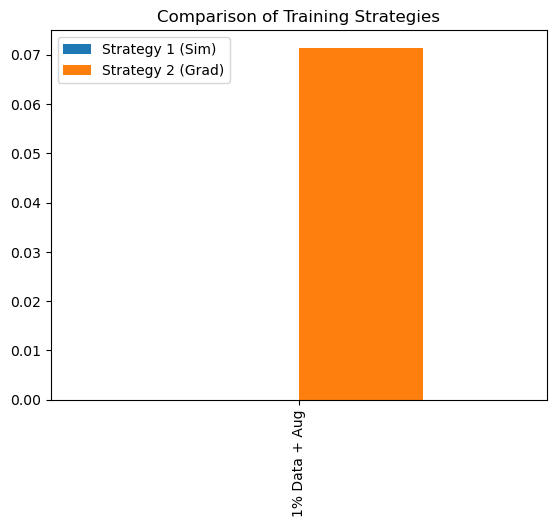

In [ ]:

import pandas as pd

# Labeling function: Uppercase = Cat (True), Lowercase = Dog (False)
def label_func(f): return f[0].isupper()
pat = r'^(.*)_\d+.jpg'


def get_dls(path, files, pat, fraction=1.0, use_aug=True):
    # Group files by breed using the regex to ensure every class is represented

    breed_to_files = {}
    # Run though the images 
    for f in files:
        # Extract breed name
        breedName = re.search(pat, f.name)
        if breedName:
            breed = breedName.group(1)

            if breed not in breed_to_files: 
                breed_to_files[breed] = []
            
            # Add image to right breed key in dictunariy
            breed_to_files[breed].append(f)


    all_breeds = sorted(list(breed_to_files.keys()))


    # Take a fraction of each breed
    sub_files = []
    for breed in breed_to_files:
        # Ensure at least 1 image, or based on defined fraction of each breed
        limit = max(1, int(len(breed_to_files[breed]) * fraction)) 
        sub_files.extend(breed_to_files[breed][:limit])
    
    # Shuffel the limited data array
    sub_files = L(sub_files).shuffle() 
    
    # Data Augmentation toggle 
    batch_tfms = aug_transforms(size=224) if use_aug else None

    # For small datasets, reduce tthe batch size
    batch_size = 64 if fraction > 0.1 else 8


    # Explicitly define the CategoryBlock with full vocabulary 
    # (For small datasets, since some classes might not be present in training causing valueError)
    
    # For larger data set use block toogled comment below instead
    dblock = DataBlock(
        blocks=(ImageBlock, CategoryBlock(vocab=all_breeds)),
        get_items=lambda x: x,
        get_y=using_attr(RegexLabeller(pat), 'name'),
        splitter=RandomSplitter(valid_pct=0.2, seed=42),
        item_tfms=Resize(448),
        batch_tfms=aug_transforms(size=224) if use_aug else None
    )
    return dblock.dataloaders(sub_files, bs=batch_size)

    """ return ImageDataLoaders.from_name_re(
        path, sub_files, pat, 
        item_tfms=Resize(448),
        batch_tfms=batch_tfms,
        valid_pct=0.2, 
        seed=42,
        bs=batch_size,
        blocks=(ImageBlock, CategoryBlock(vocab=all_breeds))
    ) """



# Create different configurations to test
dls_configs = [
    {"name": "10% Data + Aug + Low Reg",  "frac": 0.1, "aug": True},
    {"name": "10% Data + No Aug + High Reg", "frac": 0.1, "aug": False},
    {"name": "1% Data + Aug + ",   "frac": 0.01, "aug": True}
]

test_configs = [
    {"name": "1% Data + Aug",   "frac": 0.01, "aug": True, "Reg": 0.01}
]

resultsSim = {}
resultsGrad = {}

# Run configurations
for config in test_configs:
    print(f"\nRunning: {config['name']}")
    
    # Get dataloader
    current_dls = get_dls(path, files, pat, fraction=config['frac'], use_aug=config['aug'])
    
    wd = config['Reg']
    # Train using strategy 2
    learnGrad = train_strategy_gradual(current_dls, wd=wd) 
    
    # Show Performance
    final_acc_grad = learnGrad.validate()[1]
    resultsGrad[config['name']] = final_acc_grad
    print(f"Strat 2 Final Accuracy for {config['name']}: {final_acc_grad:.4f}")

""" # Evaluation
df_results = pd.DataFrame([resultsSim, resultsGrad], index=['Strategy 1 (Sim)', 'Strategy 2 (Grad)']).T
print("\nSummary Table")
print(df_results)
df_results.plot(kind='bar', title='Comparison of Training Strategies') """


Classinbalance

Experiment 1: Imbalanced
1


<div></div>

epoch,train_loss,valid_loss,accuracy,time
0,1.494178,0.415709,0.866545,05:04


2


<div></div>

...

3


<div></div>

epoch,train_loss,valid_loss,accuracy,time
0,0.214176,0.140817,0.959142,10:04



Results: Oversampled data


                            precision    recall  f1-score   support

                Abyssinian       1.00      1.00      1.00        79
                    Bengal       1.00      1.00      1.00        61
                    Birman       1.00      1.00      1.00        79
                    Bombay       1.00      1.00      1.00        73
         British_Shorthair       1.00      1.00      1.00        78
              Egyptian_Mau       1.00      1.00      1.00        76
                Maine_Coon       0.99      1.00      0.99        85
                   Persian       1.00      1.00      1.00        84
                   Ragdoll       1.00      1.00      1.00        86
              Russian_Blue       1.00      1.00      1.00        75
                   Siamese       1.00      1.00      1.00        83
                    Sphynx       1.00      1.00      1.00        74
          american_bulldog       0.80      0.82      0.81        44
 american_pit_bull_terrier       0.84      0.84

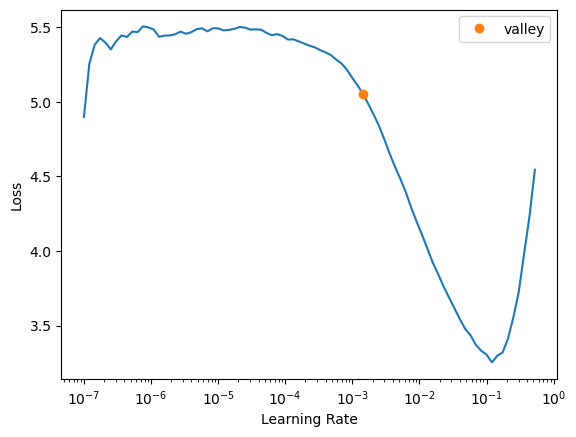

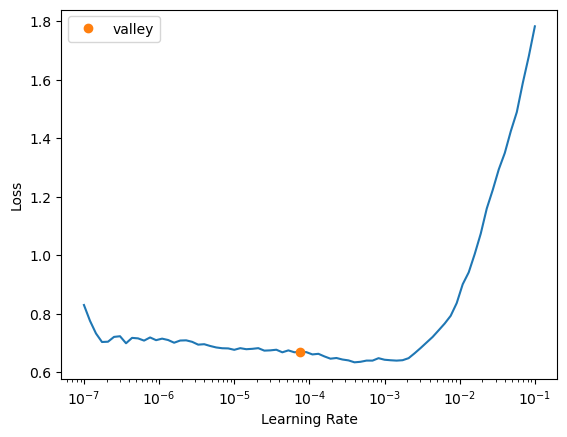

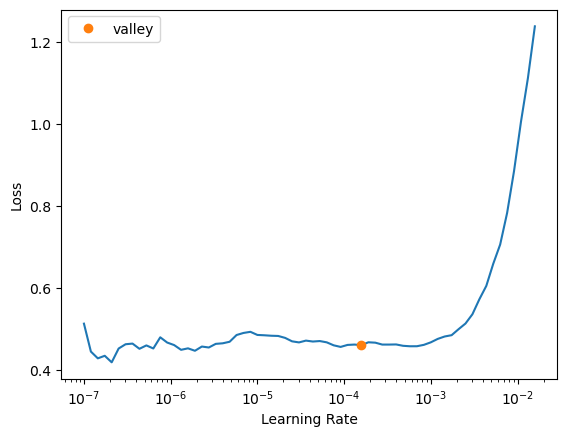

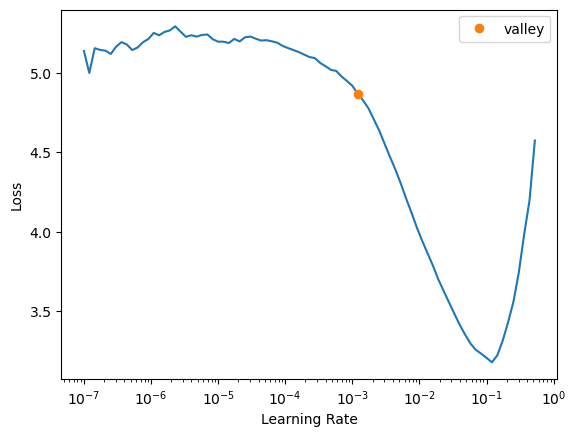

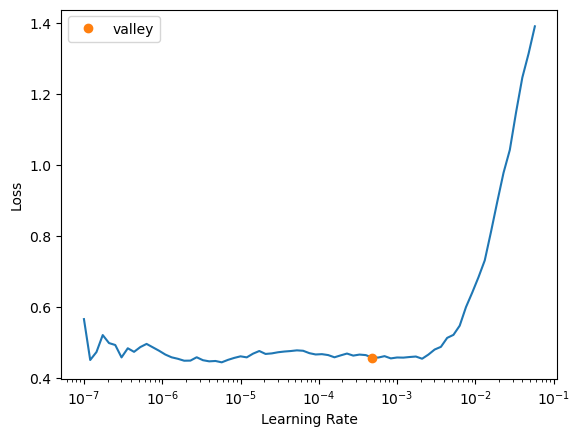

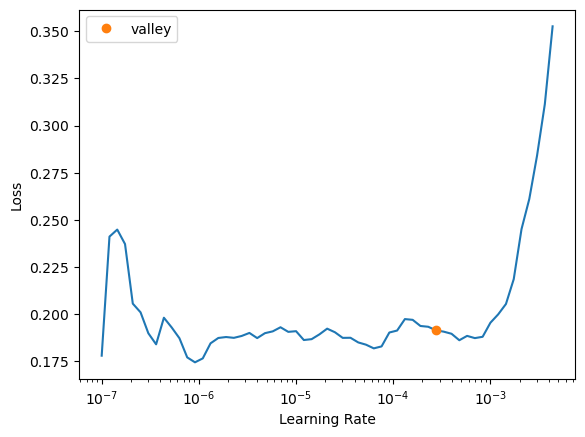

In [ ]:
import random
import re
from sklearn.metrics import classification_report

"""Creates imbalance: Keeps 100% of dogs but only fraction of cats"""
def get_imbalanced_files(files, cat_reduction=0.2):
    random.seed(42) # deterministic
    
    # Sort breeds first
    breed_to_files = {}

    # Run though the images 
    for f in files:
        # Extract breed name
        breedName = re.search(pat, f.name)
        if breedName:
            breed = breedName.group(1)

            if breed not in breed_to_files: 
                breed_to_files[breed] = []
            
            # Add image to right breed key in dictunariy
            breed_to_files[breed].append(f)


    # Create imalanced dataset
    imbalanced_files = []
    for breed, f_list in breed_to_files.items():
        # Find cat 
        if breed[0].isupper():
            num_to_keep = int(len(f_list) * cat_reduction)
            imbalanced_files.extend(random.sample(f_list, num_to_keep))
        # Else dog
        else: 
            imbalanced_files.extend(f_list)
            
    return L(imbalanced_files)


"""Multiply cat images to match the dog population, to minimize class inbalance """
def get_oversampled_files(imb_files):
    # Identify cats (Uppercase) and dogs (lowercase)
    cats = [f for f in imb_files if re.search(pat, f.name).group(1)[0].isupper()]
    dogs = [f for f in imb_files if re.search(pat, f.name).group(1)[0].islower()]
    
    # Calculate how many times we need to repeat cats to match dogs
    multiplier = len(dogs) // len(cats) if len(cats) > 0 else 1

    if multiplier < 1: multiplier = 1 
    
    oversampled_files = dogs + (cats * multiplier)
    return L(oversampled_files)


"""Prints F1-score and per-class metrics using scikit-learn"""
def print_evaluation(learn):
    preds, targs = learn.get_preds()
    pred_classes = preds.argmax(dim=1)

    print(classification_report(targs, pred_classes, target_names=learn.dls.vocab, zero_division=0))


print("Experiment 1: Imbalanced")
imb_files = get_imbalanced_files(files, cat_reduction=0.2)
# use use_aug=False to effect of imbalance
dls_imb = get_dls(path, imb_files, pat, fraction=1.0, use_aug=False) 

# Train using startegy 2
learn_imb = train_strategy_gradual(dls_imb, wd=0.01)

print("\nResults: Imbalanced data")
print_evaluation(learn_imb)



print("\nExperiment 2: oversampling")
over_files = get_oversampled_files(imb_files)
dls_over = get_dls(path, over_files, pat, fraction=1.0, use_aug=False)
learn_over = train_strategy_gradual(dls_over, wd=0.01)

print("\nResults: Oversampled data")
print_evaluation(learn_over)

"""
Data leakage in the OverSampled data, same image might apear both in training and
validation sets since the sampling is performed before the split. Menaing memorization 
instead of generlalization, overfonfident accuracy for some catbreeds.
"""


